## Part B

### Prepare

In [11]:
#import lib
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.datasets import load_iris
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [12]:
#load the dataset
iris = load_iris(as_frame=True)

data = iris.data
y = iris.target

#standardize
scaler = StandardScaler()
X = scaler.fit_transform(data)

print("Original data shape:", data.shape)
print("Standardized data shape:", X.shape)

print("Feature means:")
print(X.mean(axis=0))

print("Feature standard deviations:")
print(X.std(axis=0))

Original data shape: (150, 4)
Standardized data shape: (150, 4)
Feature means:
[-4.73695157e-16 -7.81597009e-16 -4.26325641e-16 -4.73695157e-16]
Feature standard deviations:
[1. 1. 1. 1.]


### Implement

In [13]:
pca = PCA(n_components=4)

X_pca = pca.fit_transform(X)

print("Explained variance:")
print(pca.explained_variance_)

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

Explained variance:
[2.93808505 0.9201649  0.14774182 0.02085386]

Explained variance ratio:
[0.72962445 0.22850762 0.03668922 0.00517871]


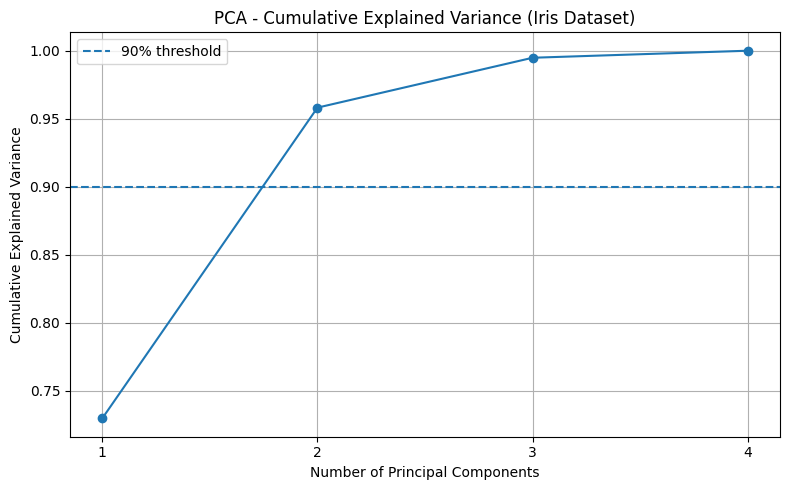

In [14]:
explained_variance_ratio = pca.explained_variance_ratio_

cumulative_variance = np.cumsum(
    explained_variance_ratio
)

plt.figure(figsize=(8, 5))

plt.plot(
    range(1, 5),
    cumulative_variance,
    marker="o"
)

plt.axhline(
    y=0.90,
    linestyle="--",
    label="90% threshold"
)

plt.xticks(range(1, 5))
plt.xlabel("Number of Principal Components")
plt.ylabel("Cumulative Explained Variance")
plt.title("PCA - Cumulative Explained Variance (Iris Dataset)")

plt.grid(True)
plt.legend()
plt.tight_layout()
plt.show()

In [15]:
#extract the first two principal components
Z = X_pca[:, :2]

print("Reduced data shape:", Z.shape)

Reduced data shape: (150, 2)


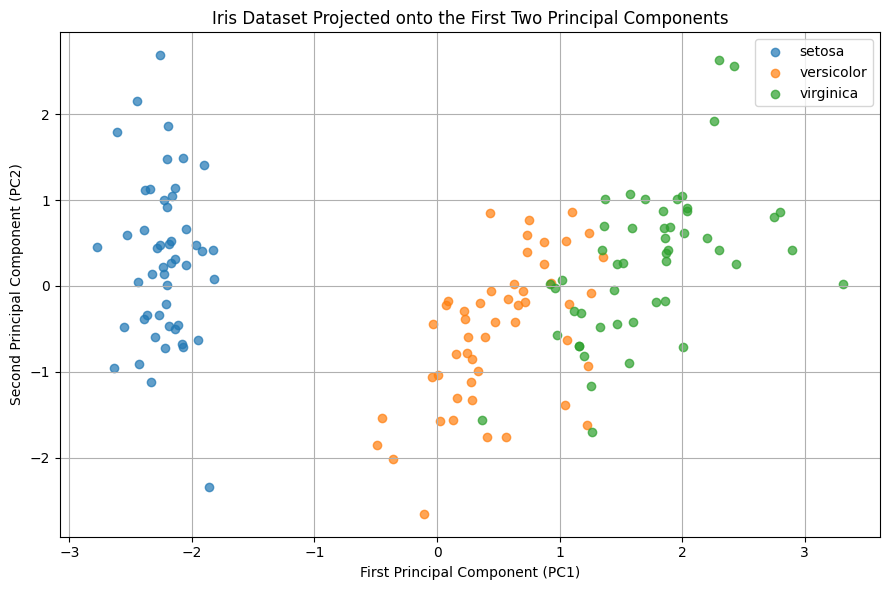

In [16]:
plt.figure(figsize=(9, 6))

species_names = iris.target_names

for i, species in enumerate(species_names):
    plt.scatter(
        Z[y == i, 0],
        Z[y == i, 1],
        label=species,
        alpha=0.7
    )

plt.xlabel("First Principal Component (PC1)")
plt.ylabel("Second Principal Component (PC2)")
plt.title("Iris Dataset Projected onto the First Two Principal Components")

plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [17]:
X_mean = X.mean(axis=0)
X_centered = X - X_mean

print("Centered data shape:", X_centered.shape)
print("Mean after centering:", X_centered.mean(axis=0))

Centered data shape: (150, 4)
Mean after centering: [ 4.73695157e-17 -2.36847579e-17  9.47390314e-17  4.73695157e-17]


In [18]:
#perform SVD
U, singular_values, Vt = np.linalg.svd(
    X_centered,
    full_matrices=False
)

print("Singular values:")
print(singular_values)

Singular values:
[20.92306556 11.7091661   4.69185798  1.76273239]


In [19]:
N = X_centered.shape[0]

#eigenvalues of population covariance matrix
S = (X_centered.T @ X_centered) / N

eigenvalues, eigenvectors = np.linalg.eigh(S)

#sort eigenvalues in descending order
idx = np.argsort(eigenvalues)[::-1]
eigenvalues = eigenvalues[idx]

#calculate eigenvalues using SVD
eigenvalues_svd = singular_values ** 2 / N

print("Eigenvalues from covariance matrix:")
print(eigenvalues)

print("\nEigenvalues from SVD:")
print(eigenvalues_svd)

print("\nDifference:")
print(eigenvalues - eigenvalues_svd)

print("\nVerification:")
print(np.allclose(eigenvalues, eigenvalues_svd))

Eigenvalues from covariance matrix:
[2.91849782 0.91403047 0.14675688 0.02071484]

Eigenvalues from SVD:
[2.91849782 0.91403047 0.14675688 0.02071484]

Difference:
[ 1.77635684e-15 -2.22044605e-15  0.00000000e+00  6.80011603e-16]

Verification:
True


In [20]:
#number of components selected from B3
M = 2

#extract the first M right singular vectors
V = Vt.T
V_M = V[:, :M]

#project the centered data
Z = X_centered @ V_M

#reconstruct the centered data
X_reconstructed_centered = Z @ V_M.T

#restore the original standardized feature means
X_reconstructed = X_reconstructed_centered + X_mean

#calculate the average squared reconstruction error
reconstruction_error = np.sum(
    (X - X_reconstructed) ** 2
) / N

print("Original data shape:", X.shape)
print("Reduced data shape:", Z.shape)
print("Reconstructed data shape:", X_reconstructed.shape)

print("\nAverage reconstruction error:")
print(reconstruction_error)

# Calculate the sum of discarded eigenvalues
discarded_variance = np.sum(eigenvalues[M:])

print("\nSum of discarded eigenvalues:")
print(discarded_variance)

print("\nDifference:")
print(abs(reconstruction_error - discarded_variance))

Original data shape: (150, 4)
Reduced data shape: (150, 2)
Reconstructed data shape: (150, 4)

Average reconstruction error:
0.16747171199993435

Sum of discarded eigenvalues:
0.16747171199993488

Difference:
5.273559366969494e-16
